# Лабораторная работа 1. Иерархический кластерный анализ

### Задание
Для каждого набора данных:

1. определить число кластеров и обосновать свой выбор;
2. разбить объекты на кластеры, предложить и обосновать интерпретацию кластеров.

### План
Часть A (леденцы) и часть B (цифры): разведочный анализ → выбор метода связи и метрики → дендрограмма и число кластеров → внутренние индексы → устойчивость → итоговое разбиение и интерпретация.

## 0. Подготовка окружения и загрузка данных

In [1]:
import sys, platform, warnings, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 11, "figure.max_open_warning": 0})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.precision", 3)

In [2]:
CANDY_PATH = "/content/Леденцы.dat"
DIGITS_PATH = "/content/digit.dat"

print("Леденцы:", CANDY_PATH, "| Цифры:", DIGITS_PATH)

Леденцы: /content/Леденцы.dat | Цифры: /content/digit.dat


In [3]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
FIG_PREFIX = "fig"

def save_show(fig, name, tight=True):
    if tight:
        fig.tight_layout()
    fig.savefig(FIG_DIR / f"{FIG_PREFIX}_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def heatmap(ax, M, xt, yt, fmt="{:.2f}", cmap="RdBu_r", vmin=None, vmax=None, annot=True, fontsize=8):
    M = np.asarray(M, float)
    vmin = np.nanmin(M) if vmin is None else vmin
    vmax = np.nanmax(M) if vmax is None else vmax
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=45, ha="right")
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    ax.grid(False)
    if annot:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                t = (M[i, j] - vmin) / (vmax - vmin + 1e-12)
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if (t < 0.2 or t > 0.8) else "black")
    return im

In [4]:
def internal_scores(X, labels, metric="euclidean"):
    return dict(silhouette=silhouette_score(X, labels, metric=metric),
                calinski_harabasz=calinski_harabasz_score(X, labels),
                davies_bouldin=davies_bouldin_score(X, labels))

def fit_kmeans(X, k, n_init=50, seed=SEED):
    return KMeans(n_clusters=k, n_init=n_init, init="k-means++", random_state=seed).fit(X)

def gap_statistic(X, ks, B=50, seed=SEED):
    rng = np.random.default_rng(seed)
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    Xp = Xc @ Vt.T
    lo, hi = Xp.min(0), Xp.max(0)
    def logW(M, k):
        return np.log(KMeans(k, n_init=5, random_state=seed).fit(M).inertia_)
    obs = np.array([logW(Xp, k) for k in ks])
    ref = np.array([[logW(rng.uniform(lo, hi, size=Xp.shape), k) for k in ks] for _ in range(B)])
    gap = ref.mean(0) - obs
    s = ref.std(0, ddof=0) * np.sqrt(1 + 1 / B)
    return pd.DataFrame({"gap": gap, "s": s}, index=list(ks))

def subsample_stability(X, k, method, ref_labels, n_rep=100, frac=0.8, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for r in range(n_rep):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        if method == "kmeans":
            lab = KMeans(k, n_init=10, random_state=r).fit_predict(X[idx])
        else:
            lab = fcluster(linkage(X[idx], "ward"), k, "maxclust")
        out.append(adjusted_rand_score(ref_labels[idx], lab))
    return np.mean(out), np.std(out)

# Часть A. Данные «Леденцы»

In [5]:
FIG_PREFIX = "candies"
DATA_PATH = CANDY_PATH

## A.1. Описание данных и разведочный анализ

In [6]:
raw = pd.read_csv(DATA_PATH, sep=";")
VARS = list(raw.columns)

VAR_TEXT = {
    "V1": "освежить дыхание",
    "V2": "чувствовать себя увереннее",
    "V3": "освежить полость рта",
    "V4": "избавиться от неприятного вкуса во рту",
    "V5": "как заменитель других кондитерских изделий",
    "V6": "когда хочется чего-нибудь сладкого",
    "V7": "помогают сконцентрироваться",
    "V8": "отвлечься на несколько минут и подумать",
    "V9": "облегчить боль в горле",
    "V10": "избавиться от заложенности носа",
    "V11": "улучшение самочувствия",
}
print("Размер выборки:", raw.shape)
display(raw.head())

Размер выборки: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


На этапе предварительного анализа данных проводится верификация следующих характеристик:

* наличие пропущенных значений;
* типы данных;
* диапазоны шкальных измерений;
* наличие дубликатов;
* структура корреляционных связей.

Совокупность полученных результатов определяет выбор подходящей метрики расстояния и обосновывает необходимость стандартизации признакового пространства.

In [7]:
print("Пропусков:", int(raw.isna().sum().sum()))
print("Типы столбцов:", raw.dtypes.unique().tolist())
print("Минимум / максимум по всей таблице:", raw.min().min(), "/", raw.max().max())

freq = raw.apply(lambda s: s.value_counts()).fillna(0).astype(int).sort_index()
display(freq.T)

Пропусков: 0
Типы столбцов: [dtype('int64')]
Минимум / максимум по всей таблице: 2 / 5


,2,3,4,5
V1,19,209,17,93
V2,24,200,26,88
V3,31,193,22,92
V4,50,174,39,75
V5,47,226,13,52
V6,48,225,13,52
V7,34,238,12,54
V8,25,244,15,54
V9,15,207,13,103
V10,15,210,25,88


**Наблюдения:**

* Пропущенные значения в массиве данных отсутствуют.
* Все 11 переменных имеют целочисленный тип и принимают значения в диапазоне от 2 до 5; минимальная градация (1) не зафиксирована, что свидетельствует о фактическом использовании четырехбалльной шкалы.
* Переменные измерены в единой шкале, в связи с чем процедура стандартизации не требуется.
* Исходная порядковая шкала трактуется как интервальная.

In [8]:
n = len(raw)
n_dup = int(raw.duplicated().sum())
patterns = raw.value_counts().rename("n").reset_index()
print(f"Строк: {n};  повторяющихся строк: {n_dup} ({n_dup/n:.1%});  уникальных профилей ответов: {len(patterns)}")
print("Покрытие выборки 4 самыми частыми профилями:", f"{patterns['n'].head(4).sum()/n:.1%}")
display(patterns.head(8))

Строк: 338;  повторяющихся строк: 293 (86.7%);  уникальных профилей ответов: 45
Покрытие выборки 4 самыми частыми профилями: 55.3%


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,n
0,3,3,3,3,3,3,5,5,3,3,3,52
1,3,3,3,3,3,3,3,3,5,5,5,49
2,5,5,5,5,3,3,3,3,3,3,3,49
3,3,3,3,3,5,5,3,3,3,3,3,37
4,3,3,3,2,2,2,2,2,5,5,5,15
5,5,5,5,4,3,3,3,3,3,3,3,12
6,3,3,3,3,5,5,3,3,2,2,2,10
7,4,5,5,5,3,3,3,3,3,3,3,10


**Важное свойство данных:**

В выборке объемом 338 респондентов зафиксирована высокая концентрация эмпирических данных: при общем числе вариантов сформировано лишь 45 уникальных профилей ответов, причем на долю четырех наиболее частотных приходится более 55 % наблюдений. Данная закономерность свидетельствует о высокой вероятности наличия чётко выраженной кластерной структуры.

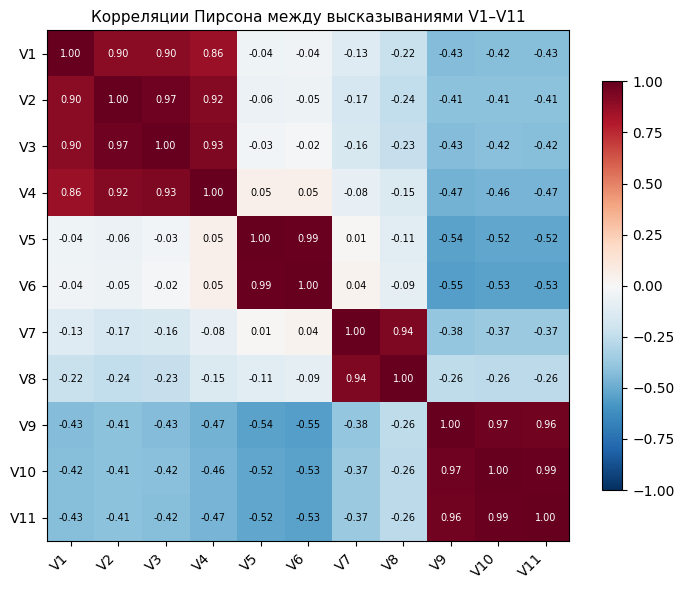

In [9]:
corr = raw.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = heatmap(ax, corr.values, VARS, VARS, cmap="RdBu_r", vmin=-1, vmax=1, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Корреляции Пирсона между высказываниями V1–V11")
save_show(fig, "corr")

**Блочная структура данных:**

Анализ корреляционной матрицы демонстрирует деление переменных на четыре обособленных блока с высокой внутригрупповой связностью (коэффициент корреляции $|\mathbf{r}| \approx 0,86–0,99$):

| Блок | Переменные | Содержательная интерпретация |
| :--- | :--- | :--- |
| **Освежение** | V1–V4 | Свежесть дыхания, гигиена полости рта, устранение неприятного привкуса, уверенность |
| **Сладкое** | V5–V6 | Замещение кондитерских изделий / сладкого |
| **Концентрация** | V7–V8 | Повышение концентрации внимания, функциональная пауза |
| **Здоровье** | V9–V11 | Облегчение боли в горле, устранение заложенности носа, улучшение общего самочувствия |

Межблочные корреляционные связи близки к нулю или имеют отрицательные значения, что свидетельствует о взаимоисключающем характере мотивационных выборов: респондент, ориентированный на реализацию одной цели, как правило, не выбирает остальные. Данная особенность предвосхищает четкую сегментацию выборки по доминирующей целевой установке. Сформированные блоки используются в дальнейшем **исключительно на этапе качественной интерпретации**, но не на этапе кластеризации.

In [10]:
BLOCKS = {
    "Свежесть":  ["V1", "V2", "V3", "V4"],
    "Сладкое":   ["V5", "V6"],
    "Фокус":     ["V7", "V8"],
    "Здоровье":  ["V9", "V10", "V11"],
}
SEG_ORDER = list(BLOCKS)

X = raw.to_numpy(dtype=float)
N = len(X)
print("X:", X.shape)

X: (338, 11)


## A.2. Выбор метода связи

Сопоставление алгоритмов иерархического объединения выполнено на основе кофенетического коэффициента корреляции и степени согласованности результирующих разбиений при фиксированном числе кластеров ($k = 4$). В качестве меры расстояния используется евклидова метрика.

,single,complete,average,weighted,centroid,median,ward
кофенетическая корреляция,0.913,0.928,0.935,0.93,0.93,0.915,0.912


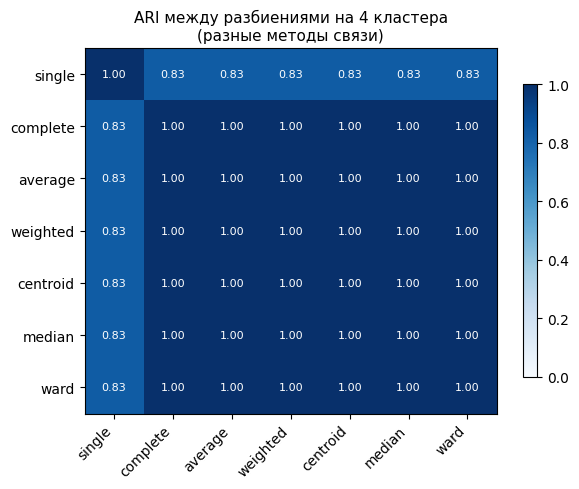

In [11]:
dist = pdist(X, metric="euclidean")
METHODS = ["single", "complete", "average", "weighted", "centroid", "median", "ward"]
links = {m: linkage(X, method=m) for m in METHODS}
coph = pd.Series({m: cophenet(links[m], dist)[0] for m in METHODS}, name="кофенетическая корреляция")
display(coph.to_frame().T)

lab4 = {m: fcluster(links[m], 4, "maxclust") for m in METHODS}
ari_mat = pd.DataFrame([[adjusted_rand_score(lab4[a], lab4[b]) for b in METHODS] for a in METHODS],
                       index=METHODS, columns=METHODS)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = heatmap(ax, ari_mat.values, METHODS, METHODS, cmap="Blues", vmin=0, vmax=1, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("ARI между разбиениями на 4 кластера\n(разные методы связи)")
save_show(fig, "linkage_ari")

**Вывод по выбору метода связи:**

Значения кофенетического коэффициента корреляции для всех рассматриваемых методов высоки и находятся в диапазоне 0,91–0,94, что указывает на их сопоставимую эффективность по данному критерию.

Ключевым фактором выбора выступают согласованность и интерпретируемость получаемых результатов: метод Уорда минимизирует внутрикластерную дисперсию, обеспечивая формирование компактных кластеров сравнимой мощности. В связи с этим в качестве базового алгоритма выбран **метод Уорда** в сочетании с евклидовой метрикой.

## A.3. Дендрограмма и число кластеров

Оптимальное число кластеров по дендрограмме определяется в точке отсечения иерархического дерева на наибольшем вертикальном интервале, что соответствует максимальному скачку высоты слияния.

,2,3,4,5,6,7,8,9,10
высота слияния k->k-1,51.706,43.442,30.218,13.030,10.216,8.492,7.187,7.178,6.551
скачок высоты,8.264,13.223,17.188,2.814,1.724,1.305,0.009,0.627,0.572


Наибольший скачок высоты слияния соответствует k = 4


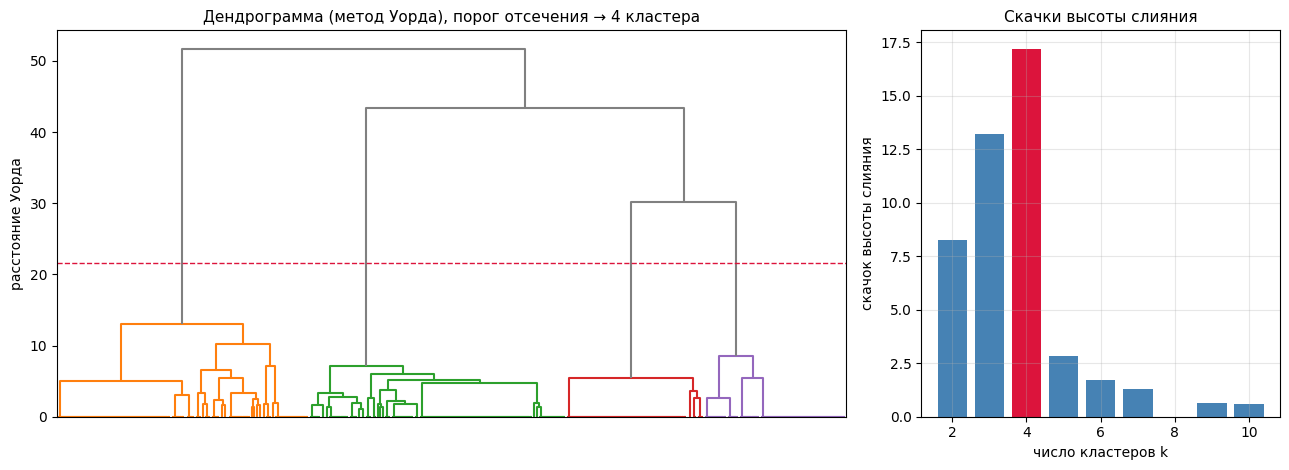

In [12]:
Z = links["ward"]
jump = pd.Series({k: Z[-(k - 1), 2] - Z[-k, 2] for k in range(2, 11)}, name="скачок высоты")
heights = pd.Series({k: Z[-(k - 1), 2] for k in range(2, 11)}, name="высота слияния k->k-1")
display(pd.concat([heights, jump], axis=1).T)
K_HIER = int(jump.idxmax())
print("Наибольший скачок высоты слияния соответствует k =", K_HIER)

cut = (Z[-K_HIER, 2] + Z[-(K_HIER - 1), 2]) / 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z, ax=axes[0], no_labels=True, color_threshold=cut, above_threshold_color="grey")
axes[0].axhline(cut, color="crimson", ls="--", lw=1)
axes[0].set_title(f"Дендрограмма (метод Уорда), порог отсечения → {K_HIER} кластера")
axes[0].set_ylabel("расстояние Уорда"); axes[0].grid(False)

ks = list(jump.index)
axes[1].bar(ks, jump.values, color=["crimson" if k == K_HIER else "steelblue" for k in ks])
axes[1].set_xlabel("число кластеров k"); axes[1].set_ylabel("скачок высоты слияния")
axes[1].set_title("Скачки высоты слияния")
save_show(fig, "dendrogram")

In [13]:
K_RANGE = list(range(2, 11))
hier_tab = pd.DataFrame({k: internal_scores(X, fcluster(Z, k, "maxclust")) for k in K_RANGE}).T
hier_tab.index.name = "k"
display(hier_tab)
print("Лучшее k: силуэт ->", int(hier_tab.silhouette.idxmax()),
      "| Calinski–Harabasz ->", int(hier_tab.calinski_harabasz.idxmax()),
      "| Davies–Bouldin (минимум) ->", int(hier_tab.davies_bouldin.idxmin()))

,silhouette,calinski_harabasz,davies_bouldin
k,,,
2,0.455,246.334,0.930
3,0.614,434.178,0.784
4,0.727,720.103,0.433
5,0.698,694.493,0.696
6,0.729,667.094,0.710
7,0.731,642.129,0.690
8,0.744,617.376,0.594
9,0.645,613.838,0.761
10,0.659,614.368,0.780


Лучшее k: силуэт -> 8 | Calinski–Harabasz -> 4 | Davies–Bouldin (минимум) -> 4


**Заключение:**

Наибольший прирост расстояния объединения ($\approx 17{,}2$ по сравнению с $\approx 13{,}2$ для $k = 3$ и $\approx 8{,}3$ для $k = 2$) наблюдается при отсечении иерархического дерева на уровне **4 кластеров**.

В рамках разбиения по методу Уорда метрики качества подтверждают выбор данной структуры: индекс Калински — Харабаса достигает максимального значения ($\approx 720$), а индекс Дэвиса — Болдина — минимального ($\approx 0{,}43$) именно при $k = 4$.

Хотя средний коэффициент силуэта принимает наивысшее значение при $k = 8$ ($0{,}744$), его отклонение от показателя при $k = 4$ ($0{,}727$) составляет лишь $0{,}017$. Выход на диапазон $k = 6–8$ ($0{,}73–0{,}74$) обусловлен фрагментацией сформированных кластеров на более мелкие группы; при этом показатели CH и DB ухудшаются, а прирост силуэта оказывается незначительным.

Таким образом, совокупный анализ дендрограммы и формальных критериев указывает на оптимальность решения с **$k = 4$**.

## A.4. Устойчивость и робастность дерева

In [14]:
stab_w = []
for k in range(2, 9):
    m = subsample_stability(X, k, "ward", fcluster(Z, k, "maxclust"))
    stab_w.append({"k": k, "Ward: ARI": m[0], "Ward: SD": m[1]})
stab_w = pd.DataFrame(stab_w).set_index("k")
display(stab_w.round(3))

Xs = StandardScaler().fit_transform(X)
lab_w4 = fcluster(Z, 4, "maxclust")
print("ARI(Ward: исходная шкала и стандартизованные признаки), k = 4:", round(adjusted_rand_score(lab_w4, fcluster(linkage(Xs, "ward"), 4, "maxclust")), 4))
print("ARI(Ward и k-средних), k = 4:", round(adjusted_rand_score(lab_w4, fit_kmeans(X, 4, n_init=100).labels_), 4))

,Ward: ARI,Ward: SD
k,,
2,0.990,0.095
3,1.000,0.000
4,1.000,0.000
5,0.993,0.011
6,0.991,0.019
7,0.992,0.012
8,0.935,0.071


ARI(Ward: исходная шкала и стандартизованные признаки), k = 4: 1.0
ARI(Ward и k-средних), k = 4: 1.0


**Заключение:**

Метод Уорда демонстрирует высокую устойчивость: при $k = 3$ и $k = 4$ структура разбиения полностью воспроизводится на подвыборках ($ARI = 1{,}00$, $\text{SD} = 0$). В диапазоне $k = 5–7$ значение индекса ARI составляет $\ge 0{,}99$, и лишь при $k = 8$ устойчивость снижается до $0{,}935$.

Полученное решение для $k = 4$ инвариантно к масштабированию признакового пространства ($ARI = 1{,}00$) и демонстрирует абсолютное совпадение с результатами, полученными методом $k$-средних ($ARI = 1{,}00$).

## A.5. Итоговое разбиение и интерпретация сегментов

In [15]:
K_FINAL = 4
labels_ward = fcluster(Z, K_FINAL, "maxclust") - 1
print(f"Метод Уорда, k = {K_FINAL}: размеры кластеров:", np.bincount(labels_ward).tolist())

Метод Уорда, k = 4: размеры кластеров: [108, 110, 59, 61]


Средний силуэт: 0.727;  респондентов с отрицательным силуэтом: 0 из 338


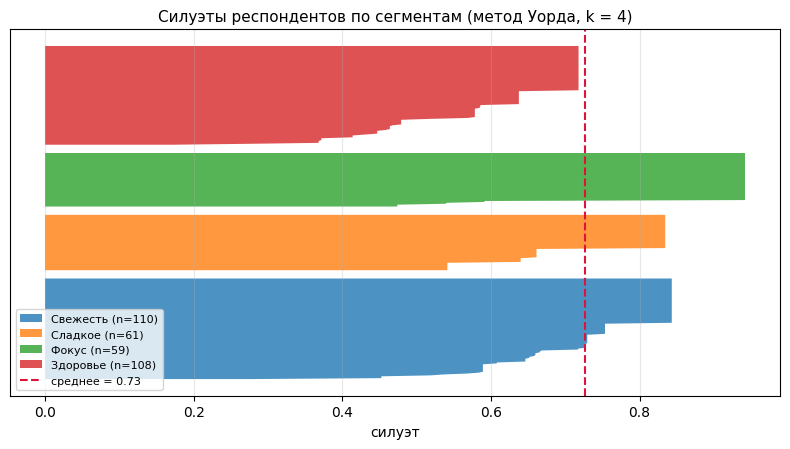

In [16]:
sil_i = silhouette_samples(X, labels_ward)
print(f"Средний силуэт: {sil_i.mean():.3f};  респондентов с отрицательным силуэтом: {(sil_i < 0).sum()} из {N}")

def name_clusters(labels, X=X, X_ref=X):
    """Имя кластера = блок высказываний, по которому среднее кластера больше всего превышает общее среднее."""
    names = {}
    for c in sorted(set(labels) - {-1}):
        centre = X[labels == c].mean(0)
        score = {b: np.mean([centre[VARS.index(v)] - X_ref[:, VARS.index(v)].mean() for v in vs]) for b, vs in BLOCKS.items()}
        names[c] = max(score, key=score.get)
    assert len(set(names.values())) == len(names), "два кластера получили одно имя — проверить разбиение"
    if -1 in labels:
        names[-1] = "Шум"
    return names

seg_ward = pd.Series(labels_ward).map(name_clusters(labels_ward))

fig, ax = plt.subplots(figsize=(8, 4.6))
y0 = 0
for seg in SEG_ORDER:
    v = np.sort(sil_i[(seg_ward == seg).to_numpy()])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.8, label=f"{seg} (n={len(v)})")
    y0 += len(v) + 8
ax.axvline(sil_i.mean(), color="crimson", ls="--", label=f"среднее = {sil_i.mean():.2f}")
ax.set(title="Силуэты респондентов по сегментам (метод Уорда, k = 4)", xlabel="силуэт", yticks=[])
ax.legend(loc="lower left", fontsize=8)
save_show(fig, "silhouette")

### Профили сегментов

In [17]:
res = raw.copy()
res["сегмент"] = pd.Categorical(seg_ward, categories=SEG_ORDER, ordered=True)

size = res["сегмент"].value_counts().reindex(SEG_ORDER)
profile = res.groupby("сегмент", observed=True)[VARS].mean().reindex(SEG_ORDER)
print("Размеры сегментов:")
display(pd.DataFrame({"n": size, "доля": size / N}).T)
print("Средние оценки по высказываниям:")
display(pd.concat([profile, raw.mean().rename("вся выборка").to_frame().T]))

top2 = res.groupby("сегмент", observed=True)[VARS].agg(lambda s: (s >= 4).mean()).reindex(SEG_ORDER)
print("Доля респондентов, согласных с высказыванием:")
display(top2)

Размеры сегментов:


сегмент,Свежесть,Сладкое,Фокус,Здоровье
n,110.000,61.00,59.000,108.00
доля,0.325,0.18,0.175,0.32


Средние оценки по высказываниям:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Свежесть,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
Сладкое,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
Фокус,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000
Здоровье,2.824,2.833,2.769,2.620,2.611,2.583,2.750,2.917,4.954,4.815,4.861
вся выборка,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565


Доля респондентов, согласных с высказыванием:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
сегмент,,,,,,,,,,,
Свежесть,1.0,1.000,1.000,1.000,0.036,0.036,0.000,0.027,0.073,0.045,0.045
Сладкое,0.0,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
Фокус,0.0,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000
Здоровье,0.0,0.037,0.037,0.037,0.000,0.000,0.065,0.065,1.000,1.000,1.000


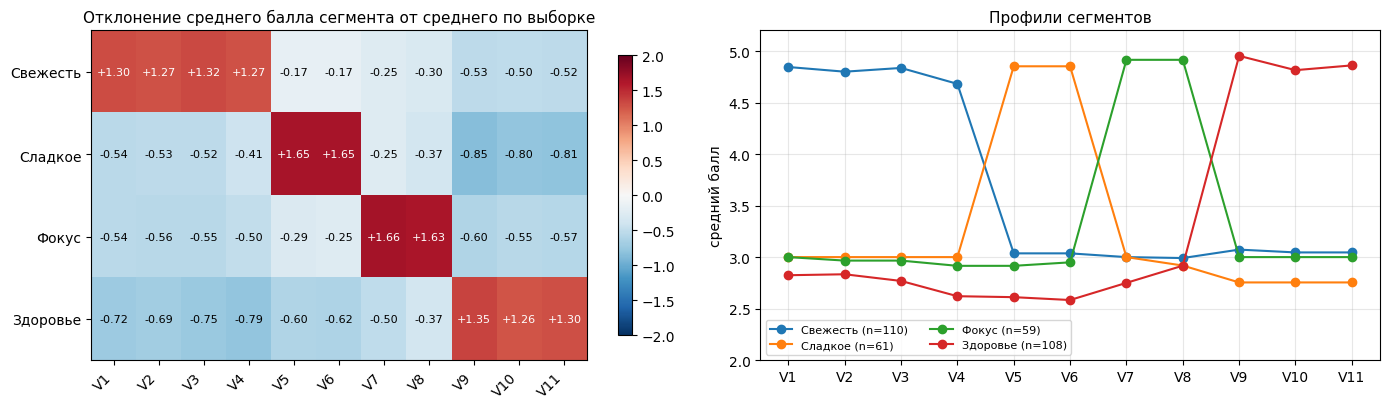

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
diff = profile - raw.mean()
im = heatmap(axes[0], diff.values, VARS, SEG_ORDER, fmt="{:+.2f}", cmap="RdBu_r", vmin=-2, vmax=2)
fig.colorbar(im, ax=axes[0], shrink=0.85)
axes[0].set_title("Отклонение среднего балла сегмента от среднего по выборке")

colors = plt.cm.tab10.colors
for i, seg in enumerate(SEG_ORDER):
    axes[1].plot(VARS, profile.loc[seg], "o-", color=colors[i], label=f"{seg} (n={size[seg]})")
axes[1].set(title="Профили сегментов", ylabel="средний балл", ylim=(2, 5.2))
axes[1].legend(fontsize=8, ncol=2)
save_show(fig, "profiles")

### 7.2. Проекция на главные компоненты

Метод главных компонент применяется исключительно в целях визуализации данных и верификации выделенной блочной структуры, в то время как процедура кластеризации выполнялась непосредственно на пространстве исходных признаков.

Для обеспечения наглядности и предотвращения наложения совпадающих наблюдений на графике к координатам был добавлен незначительный случайный шум, затрагивающий исключительно графическое представление.

Доля объяснённой дисперсии: [0.499, 0.281, 0.151, 0.036] | накопленная: [0.499, 0.78, 0.931, 0.967]


,PC1,PC2,PC3,PC4
V1,0.360,-0.280,0.044,0.023
V2,0.366,-0.308,0.035,0.098
V3,0.385,-0.308,0.029,0.153
V4,0.393,-0.251,0.041,0.339
V5,0.141,0.344,-0.455,0.375
V6,0.146,0.352,-0.442,0.382
V7,0.040,0.305,0.528,0.364
V8,-0.007,0.269,0.552,0.318
V9,-0.372,-0.302,-0.047,0.279
V10,-0.353,-0.290,-0.053,0.358


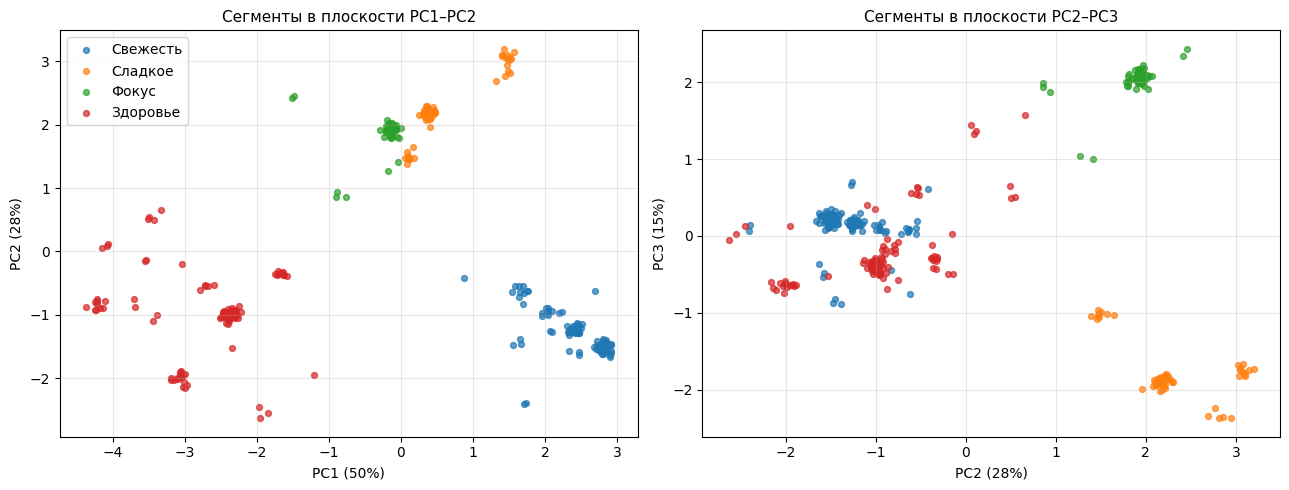

In [19]:
pca = PCA(n_components=4, random_state=SEED).fit(X)
P = pca.transform(X)
load = pd.DataFrame(pca.components_.T, index=VARS, columns=[f"PC{i+1}" for i in range(4)])
print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_.round(3).tolist(),
      "| накопленная:", pca.explained_variance_ratio_.cumsum().round(3).tolist())
display(load)

rng = np.random.default_rng(SEED)
J = P + rng.normal(0, 0.06, P.shape)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (a, b), ax in zip([(0, 1), (1, 2)], axes):
    for i, seg in enumerate(SEG_ORDER):
        msk = (seg_ward == seg).to_numpy()
        ax.scatter(J[msk, a], J[msk, b], s=18, alpha=0.7, color=colors[i], label=seg)
    ax.set(xlabel=f"PC{a+1} ({pca.explained_variance_ratio_[a]:.0%})", ylabel=f"PC{b+1} ({pca.explained_variance_ratio_[b]:.0%})")
axes[0].legend(); axes[0].set_title("Сегменты в плоскости PC1–PC2"); axes[1].set_title("Сегменты в плоскости PC2–PC3")
save_show(fig, "pca")

Первые три главные компоненты кумулятивно описывают около 93 % общей дисперсии, а четыре — порядка 97 %. Фактическая размерность пространства данных составляет три, что согласуется с наличием четырех центроидов кластеров. На плоскостях проекций выделенные сегменты формируют четыре компактные области, что визуально подтверждает высокую чёткость и обособленность полученного разбиения.

### 7.3. Содержательная интерпретация сегментов

### Содержательная интерпретация

In [20]:
for seg in SEG_ORDER:
    dom = profile.loc[seg].sort_values(ascending=False)
    top = dom[dom >= 4].index.tolist()
    low = profile.loc[seg][profile.loc[seg] < 3].index.tolist()
    print(f"{seg:<9} n={size[seg]:>3} ({size[seg]/N:.1%}) | высокие (≥4): {', '.join(top)} | ниже нейтрального 3: {', '.join(low) if low else '—'}")

Свежесть  n=110 (32.5%) | высокие (≥4): V1, V3, V2, V4 | ниже нейтрального 3: V8
Сладкое   n= 61 (18.0%) | высокие (≥4): V5, V6 | ниже нейтрального 3: V8, V9, V10, V11
Фокус     n= 59 (17.5%) | высокие (≥4): V7, V8 | ниже нейтрального 3: V2, V3, V4, V5, V6
Здоровье  n=108 (32.0%) | высокие (≥4): V9, V11, V10 | ниже нейтрального 3: V1, V2, V3, V4, V5, V6, V7, V8


В результате проведенной сегментации выделены четыре устойчивые группы потребителей, полностью удовлетворяющие базовым маркетинговым критериям: интерпретируемости (каждая группа имеет четкую доминирующую цель), измеримости (профиль однозначно восстанавливается по 2–4 индикаторам) и достаточной емкости (наименьший сегмент составляет $17{,}5\,\%$ совокупности).

| Сегмент | Доля | Доминирующая цель потребления | Интерпретация и стратегические рекомендации |
| :--- | :--- | :--- | :--- |
| **«Свежесть»**<br>($V_1–V_4$) | $\approx 32{,}5\,\%$ | Освежение дыхания и полости рта, устранение неприятного привкуса, повышение уверенности в коммуникации | Потребление носит функционально-гигиенический характер. Ключевые требования: выраженный мятный профиль, пролонгированный освежающий эффект, коммуникация через атрибут уверенности в социальных контактах. |
| **«Здоровье»**<br>($V_9–V_{11}$) | $\approx 32{,}0\,\%$ | Облегчение болевых ощущений в горле, купирование заложенности носа, улучшение общего состояния | Функциональное (лечебно-профилактическое) потребление с вероятным сезонным всплеском. Приоритетные факторы: натуральный состав (лекарственные травы, ментол, эвкалипт), дистрибуция через аптечный канал, позиционирование в парадигме заботы о здоровье. |
| **«Сладкое»**<br>($V_5–V_6$) | $\approx 18{,}0\,\%$ | Замещение кондитерских изделий, удовлетворение потребности в сладком | Леденец выступает в качестве альтернативы десерту. Критичные параметры: вкусовые характеристики, разнообразие ассортиментной линейки, ценовой фактор, ориентация на импульсный спрос (размещение в прикассовых зонах). |
| **«Фокус»**<br>($V_7–V_8$) | $\approx 17{,}5\,\%$ | Стимуляция концентрации внимания, организация когнитивной паузы | Использование продукта как инструмента в профессиональной деятельности или учебе. Перспективные направления: таргетинг на офисных сотрудников и студенческую аудиторию, акцент на позиционировании «продуктивность и фокус». |

**Анализ профилей мотивации:**

Полученные сегменты демонстрируют специфические паттерны восприятия альтернативных целевых установок. В группах «Здоровье», «Сладкое» и «Фокус» средние оценки по нецелевым направлениям падают ниже нейтрального порога в 3 балла (в сегменте «Здоровье» — вплоть до $0{,}4$ балла), что свидетельствует об осознанном отвержении респондентами прочих мотиваций и высокой степени концентрации на доминирующей цели. Исключением выступает сегмент «Свежесть», средние оценки которого по остальным целям удерживаются вблизи нейтрального уровня.

## A.6. Вложенность кластеров в дереве

In [21]:
for k in (2, 3, 6):
    lab_k = fcluster(Z, k, "maxclust")
    print(f"Разрез на k = {k} кластеров (по строкам) и итоговые сегменты k = 4 (по столбцам):")
    display(pd.crosstab(pd.Series(lab_k, name=f"кластер k={k}"), seg_ward.rename("сегмент k=4"))[SEG_ORDER])

Разрез на k = 2 кластеров (по строкам) и итоговые сегменты k = 4 (по столбцам):


сегмент k=4,Свежесть,Сладкое,Фокус,Здоровье
кластер k=2,,,,
1,0,0,0,108
2,110,61,59,0


Разрез на k = 3 кластеров (по строкам) и итоговые сегменты k = 4 (по столбцам):


сегмент k=4,Свежесть,Сладкое,Фокус,Здоровье
кластер k=3,,,,
1,0,0,0,108
2,110,0,0,0
3,0,61,59,0


Разрез на k = 6 кластеров (по строкам) и итоговые сегменты k = 4 (по столбцам):


сегмент k=4,Свежесть,Сладкое,Фокус,Здоровье
кластер k=6,,,,
1,0,0,0,59
2,0,0,0,29
3,0,0,0,20
4,110,0,0,0
5,0,0,59,0
6,0,61,0,0


**Иерархия сегментов:**

Структура иерархического дерева наглядно отражает последовательность формирования потребительских групп:

* При разбиении на **$k = 2$** в первую очередь отделяется сегмент «Здоровье» ($108$ респондентов) от остальных трех групп ($228$ респондентов), что подчеркивает его наибольшую обособленность.
* При **$k = 3$** происходит объединение сегментов «Сладкое» и «Фокус» ($120$ респондентов) как наиболее близких между собой, в то время как сегмент «Свежесть» отделяется на следующем уровне иерархии ($k = 4$).
* При дальнейшем детальном дроблении до **$k = 6$** расщеплению подвергается исключительно сегмент «Здоровье», разделяясь на подгруппы численностью 59, 29 и 20 респондентов, тогда как остальные три сегмента сохраняют свою стабильность.

Данный факт подтверждает, что увеличение числа кластеров сверх $k = 4$ не приводит к выделению новых содержательных сегментов, а лишь детализирует внутреннюю структуру группы «Здоровье».

### Выводы по части A

1. **Метод межгруппового связывания:** Значения кофенетического коэффициента корреляции у всех рассматриваемых алгоритмов сопоставимы ($0{,}91–0{,}94$). В качестве базового выбран **метод Уорда**, обеспечивающий формирование компактных кластеров сравнимой мощности; при уровне $k = 4$ он демонстрирует полное совпадение результатов с методами *average*, *complete*, *weighted* и *centroid*.
2. **Оптимальное число кластеров:** Наибольший прирост высоты объединения зафиксирован при переходе к $k = 4$ ($\approx 17{,}2$ против $\approx 13{,}2$ для $k = 3$ и $\approx 8{,}3$ для $k = 2$). На данном уровне индекс Калински — Харабаса достигает максимума ($\approx 720{,}1$), индекс Дэвиса — Болдина — минимума ($\approx 0{,}433$); полученное разбиение обладает абсолютной устойчивостью на подвыборках ($ARI = 1{,}00$) и инвариантно к процедуре стандартизации.
3. **Содержательная интерпретация:** Выделены четыре устойчивые группы потребителей в соответствии с доминирующей целью потребления: «Свежесть» ($110$ респондентов; $32{,}5\,\%$), «Здоровье» ($108$; $32{,}0\,\%$), «Сладкое» ($61$; $18{,}0\,\%$) и «Фокус» ($59$; $17{,}5\,\%$). Согласно иерархической структуре дерева, сегмент «Здоровье» выступает наиболее обособленным, в то время как группы «Сладкое» и «Фокус» проявляют наибольшую близость.
4. **Методические ограничения:** Анализируемый массив данных сформирован из $45$ уникальных профилей ответов; шкала измерений фактически функционирует в диапазоне значений от 2 до 5, при этом исходные порядковые данные трактуются как интервальные.

# Часть B. Данные «Цифры»

In [22]:
FIG_PREFIX = "digits"
DATA_PATH = DIGITS_PATH

## B.1. Описание данных и разведочный анализ

In [23]:
raw = pd.read_csv(DATA_PATH, sep=";", dtype=str).apply(lambda s: s.str.strip())
SEG = list("BCDEFGH")
assert (raw[SEG].to_numpy() == raw[[s + "2" for s in SEG]].to_numpy()).all() and (raw["A"] == raw["A2"]).all(), "дубли столбцов не совпадают"
print("Значения признаков:", sorted(set(raw[SEG].to_numpy().ravel())), "| значения A:", sorted(raw["A"].str.lower().unique()))

X = (raw[SEG] == "ONE").astype(int).to_numpy()
y = raw["A"].str.lower().to_numpy()
N = len(X)
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
DIGIT_NUM = {d: i for i, d in enumerate(DIGITS)}
print(f"Объектов: {N}; признаков: {X.shape[1]}; уникальных комбинаций сегментов: {len(np.unique(X, axis=0))} из 128 возможных")

Значения признаков: ['ONE', 'ZERO'] | значения A: ['eight', 'five', 'four', 'nine', 'one', 'seven', 'six', 'three', 'two', 'zero']
Объектов: 500; признаков: 7; уникальных комбинаций сегментов: 75 из 128 возможных


### Проверка корректности кодирования и уровня шума

Эталонная матрица начертаний цифр для семисегментного индикатора строится на основе следующей топологии элементов: `B` — верхний горизонтальный, `C` — верхний левый вертикальный, `D` — верхний правый вертикальный, `E` — средний горизонтальный, `F` — нижний левый вертикальный, `G` — нижний правый вертикальный, `H` — нижний горизонтальный.

Данные эталонные конфигурации применяются **исключительно** для верификации схемы кодирования и количественной оценки уровня искажений; процедура кластеризации выполняется без их непосредственного использования.

In [24]:
CANON = {"zero":  [1, 1, 1, 0, 1, 1, 1], "one":   [0, 0, 1, 0, 0, 1, 0], "two":   [1, 0, 1, 1, 1, 0, 1],
         "three": [1, 0, 1, 1, 0, 1, 1], "four":  [0, 1, 1, 1, 0, 1, 0], "five":  [1, 1, 0, 1, 0, 1, 1],
         "six":   [1, 1, 0, 1, 1, 1, 1], "seven": [1, 0, 1, 0, 0, 1, 0], "eight": [1] * 7, "nine":  [1, 1, 1, 1, 0, 1, 1]}
CANON["seven"] = [1, 0, 1, 0, 0, 1, 0]
Cmat = np.array([CANON[d] for d in y])

print(f"Согласие с эталонами при ONE = «горит»: {(X == Cmat).mean():.3f}")
print(f"Согласие с эталонами при инверсии: {(X != Cmat).mean():.3f}")
print(f"Доля искажённых сегментов: {(X != Cmat).mean():.3f}")
print(f"Доля цифр, записанных без единой ошибки: {(X == Cmat).all(1).mean():.3f}")
nearest = np.array([min(CANON, key=lambda k: (x != np.array(CANON[k])).sum()) for x in X])
print(f"Потолок для безэталонной кластеризации: {(nearest == y).mean():.3f}")

freq = pd.Series(y).value_counts().reindex(DIGITS)
prof_true = pd.DataFrame(X, columns=SEG).groupby(y).mean().reindex(DIGITS)
print("\nЧисло объектов по цифрам:", freq.to_dict())
display(prof_true.round(2))

Согласие с эталонами при ONE = «горит»: 0.901
Согласие с эталонами при инверсии: 0.099
Доля искажённых сегментов: 0.099
Доля цифр, записанных без единой ошибки: 0.488
Потолок для безэталонной кластеризации: 0.746

Число объектов по цифрам: {'zero': 42, 'one': 43, 'two': 43, 'three': 55, 'four': 52, 'five': 54, 'six': 50, 'seven': 48, 'eight': 58, 'nine': 55}


,B,C,D,E,F,G,H
zero,0.90,0.86,0.98,0.12,0.90,0.93,0.88
one,0.09,0.07,0.93,0.09,0.21,0.88,0.16
two,0.88,0.09,0.81,0.93,0.88,0.02,0.93
three,0.91,0.15,0.91,0.93,0.15,0.95,0.85
four,0.08,0.87,0.88,0.98,0.15,0.88,0.12
five,0.91,0.98,0.15,0.98,0.11,0.93,0.89
six,0.90,0.88,0.02,0.88,0.94,0.90,0.88
seven,0.88,0.15,0.88,0.12,0.08,0.92,0.08
eight,0.91,0.95,0.90,0.97,0.83,0.88,0.88
nine,0.95,0.80,0.87,0.96,0.07,0.91,0.91


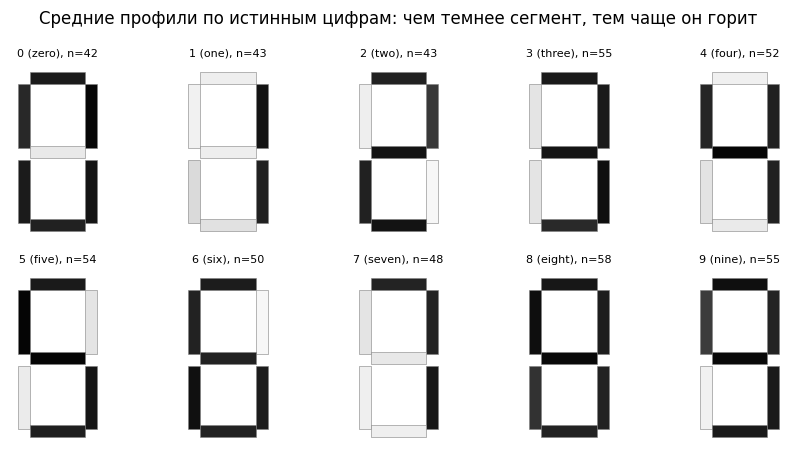

In [25]:
def draw_digit(ax, probs, title=None, fs=8):
    geom = {"B": (0.15, 1.85, 0.7, 0.15), "C": (0.0, 1.05, 0.15, 0.8), "D": (0.85, 1.05, 0.15, 0.8),
            "E": (0.15, 0.925, 0.7, 0.15), "F": (0.0, 0.1, 0.15, 0.8), "G": (0.85, 0.1, 0.15, 0.8), "H": (0.15, 0.0, 0.7, 0.15)}
    for s, pr in zip(SEG, probs):
        x0, y0, w, h = geom[s]
        ax.add_patch(plt.Rectangle((x0, y0), w, h, facecolor=plt.cm.Greys(0.05 + 0.95 * float(pr)), edgecolor="grey", lw=0.4))
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 2.1); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize=fs)

fig, axes = plt.subplots(2, 5, figsize=(9, 4.6))
for ax, d in zip(axes.ravel(), DIGITS):
    draw_digit(ax, prof_true.loc[d].to_numpy(), f"{DIGIT_NUM[d]} ({d}), n={freq[d]}")
fig.suptitle("Средние профили по истинным цифрам: чем темнее сегмент, тем чаще он горит")
save_show(fig, "true_profiles")

**Наблюдения:**

Эмпирические профили каждой цифры демонстрируют в целом высокое соответствие эталонным конфигурациям, однако около $10\,\%$ индивидуальных сегментов содержат искажения, а полностью безошибочная запись характерна лишь примерно для половины исследуемых знаков.

Даже гипотетический идеальный классификатор, функционирующий по критерию ближайшего эталона с априорным знанием всех десяти базовых начертаний, способен обеспечить точность не выше $\approx 75\,\%$. В связи с этим формирование идеально «чистых» кластеров методологически недостижимо: часть цифровых знаков обладает высокой степенью структурного пересечения, например, символы `1` и `7` различаются всего одним элементом.

Данное обстоятельство определяет объективный верхний предел эффективности и задает реалистичный уровень ожиданий от процедур безэталонной кластеризации.

## B.2. Иерархический анализ: метод связи, дендрограмма, число кластеров

**Метрика различий:**

Поскольку анализируемые признаки имеют бинарную природу, в качестве естественной меры различия выступает расстояние Хэмминга, определяемое количеством несовпадающих сегментов.

Для данных типа $0/1$ квадрат евклидова расстояния математически эквивалентен расстоянию Хэмминга, что обеспечивает методологическую корректность применения метода Уорда, опирающегося на евклидову метрику. В свою очередь, для алгоритмов иерархического кластерного анализа на основе одиночной, полной и средней связей расстояние Хэмминга применяется напрямую.

,single,complete,average,weighted,ward
кофенетическая корреляция,0.406,0.504,0.657,0.54,0.636


,2,3,4,5,6,7,8,9,10,11,12,13,14,15
высота слияния k->k-1,16.10,11.09,10.49,10.45,9.81,8.09,7.32,6.22,6.16,5.91,5.78,5.34,5.33,5.09
скачок высоты,5.01,0.59,0.04,0.65,1.71,0.78,1.10,0.06,0.25,0.13,0.44,0.01,0.25,0.39


Скачки по убыванию: {2: 5.01, 6: 1.71, 8: 1.1, 7: 0.78, 5: 0.65}


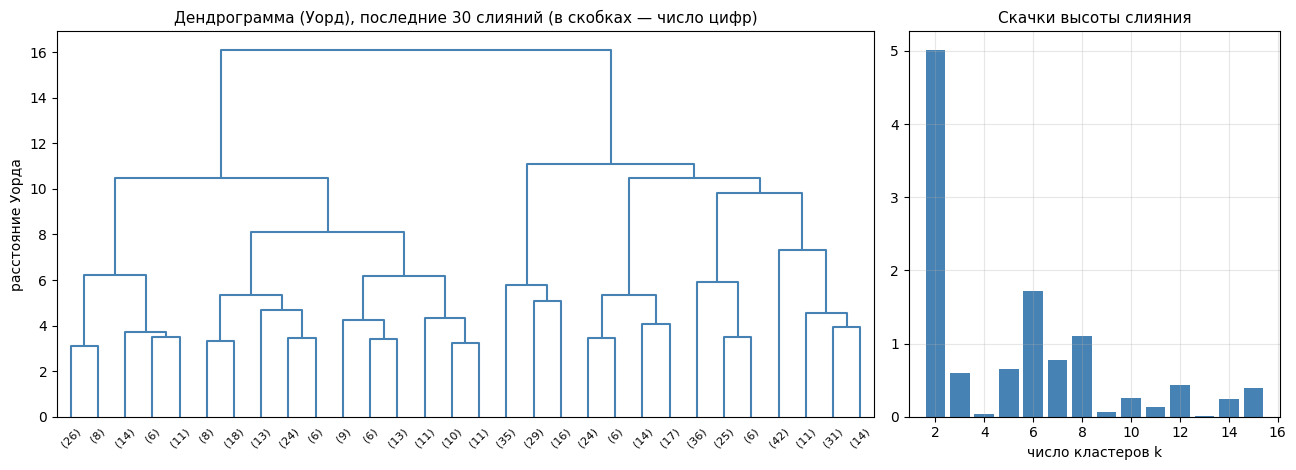

,silhouette,calinski_harabasz,davies_bouldin
k,,,
2,0.313,110.187,2.050
3,0.215,90.557,1.892
4,0.247,86.720,1.702
5,0.288,89.775,1.594
6,0.316,94.050,1.406
7,0.343,93.957,1.589
8,0.298,93.513,1.472
9,0.319,91.265,1.421
10,0.342,90.511,1.327


In [26]:
d_h = pdist(X, "hamming")
links = {m: linkage(X, m, metric="hamming") for m in ["single", "complete", "average", "weighted"]}
links["ward"] = linkage(X, "ward")
coph = pd.Series({m: cophenet(Z_, d_h if m != "ward" else pdist(X))[0] for m, Z_ in links.items()}, name="кофенетическая корреляция")
display(coph.to_frame().T)

Z = links["ward"]
K_RANGE = list(range(2, 16))
jump = pd.Series({k: Z[-(k - 1), 2] - Z[-k, 2] for k in range(2, 16)}, name="скачок высоты")
heights = pd.Series({k: Z[-(k - 1), 2] for k in range(2, 16)}, name="высота слияния k->k-1")
display(pd.concat([heights, jump], axis=1).T.round(2))
print("Скачки по убыванию:", jump.sort_values(ascending=False).round(2).head(5).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z, truncate_mode="lastp", p=30, ax=axes[0], show_leaf_counts=True, leaf_font_size=8, color_threshold=0.0, above_threshold_color="steelblue")
axes[0].set(title="Дендрограмма (Уорд), последние 30 слияний (в скобках — число цифр)", ylabel="расстояние Уорда"); axes[0].grid(False)
axes[1].bar(jump.index, jump.values, color="steelblue"); axes[1].set(title="Скачки высоты слияния", xlabel="число кластеров k")
save_show(fig, "dendrogram")

hier_tab = pd.DataFrame({k: internal_scores(X, fcluster(Z, k, "maxclust"), metric="hamming") for k in K_RANGE}).T
hier_tab.index.name = "k"
display(hier_tab)

**Заключение:**

Иерархическая структура анализируемых данных выражена слабо: значения кофенетического коэффициента корреляции существенно ниже по сравнению с предыдущими задачами; для метода среднего межгруппового расстояния — $0{,}657$, метода Уорда — $0{,}636$, полного связывания — $0{,}50$, одиночного связывания — $0{,}41$, что во многом обусловлено проявлением эффекта цепеобразования.

На дендрограмме, построенной методом Уорда, наибольший прирост высоты слияния наблюдается при $k = 2$ ($5{,}0$), тогда как локальные скачки фиксируются при $k = 6$ ($1{,}7$) и $k = 8$ ($1{,}1$). Внутренние критерии качества разбиения демонстрируют немонотонный характер и принимают сравнительно низкие значения; коэффициент силуэта находится в диапазоне $0{,}22–0{,}44$, а индекс Калински — Харабаса максимален при $k = 2$, что указывает на отсутствие четко выраженного глобального оптимума.

Кроме того, метод Уорда заметно уступает алгоритму $k$-средних при равном числе кластеров. Данный эффект объясняется спецификой стратегии иерархического объединения: ошибки, допущенные на ранних итерациях, не подлежат коррекции на последующих шагах, а присутствие около $10\,\%$ искаженных сегментов предопределяет неудачный характер начальных слияний.

## B.3. Внешняя проверка, устойчивость и сравнение методов связи

Переменная $A$, определяющая истинное значение цифры, **не участвует в процедуре кластеризации** и привлекается исключительно в качестве внешнего критерия для оценки степени согласованности иерархических разбиений с реальными классами.

In [27]:
def purity(y_true, lab):
    return pd.crosstab(lab, y_true).max(axis=1).sum() / len(y_true)

def external_scores(lab):
    return dict(ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab),
                однородность=homogeneity_score(y, lab), полнота=completeness_score(y, lab), purity=purity(y, lab))

,ARI,NMI,однородность,полнота,purity
k,,,,,
2,0.084,0.182,0.117,0.403,0.190
3,0.136,0.269,0.194,0.437,0.252
4,0.177,0.318,0.248,0.443,0.314
5,0.226,0.351,0.293,0.439,0.390
6,0.281,0.399,0.352,0.461,0.454
7,0.307,0.421,0.387,0.461,0.454
8,0.319,0.434,0.412,0.458,0.498
9,0.314,0.444,0.430,0.459,0.498
10,0.326,0.450,0.444,0.456,0.508


k,2,3,4,5,6,7,8,9,10,11,12,13,14
Ward: ARI,0.465,0.311,0.347,0.399,0.481,0.503,0.543,0.561,0.575,0.576,0.612,0.623,0.649
Ward: SD,0.209,0.187,0.139,0.112,0.103,0.087,0.066,0.064,0.064,0.058,0.055,0.049,0.045


,силуэт,ARI,NMI,purity,размер крупнейшего
метод связи,,,,,
single,0.304,0.000,0.004,0.118,499
complete,0.262,0.265,0.396,0.452,121
average,0.360,0.332,0.495,0.482,146
weighted,0.260,0.247,0.406,0.410,136
ward,0.342,0.326,0.450,0.508,80


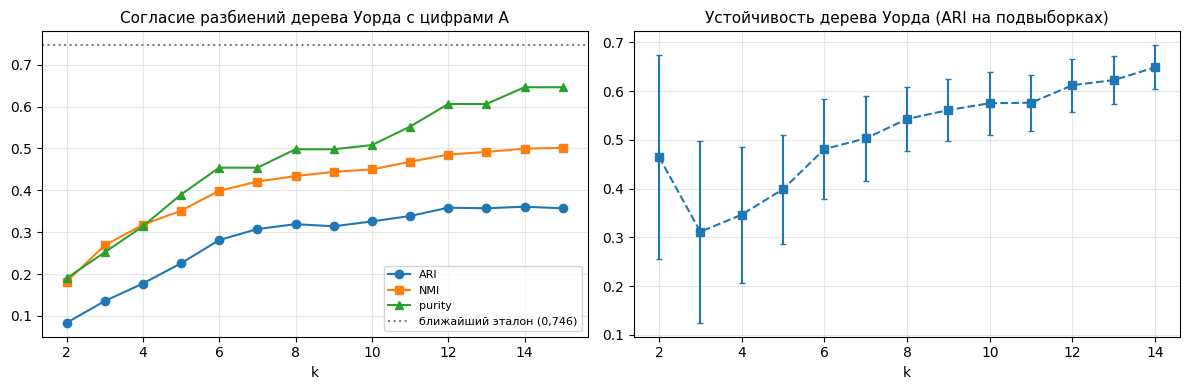

In [28]:
ext_wd = pd.DataFrame({k: external_scores(fcluster(Z, k, "maxclust")) for k in K_RANGE}).T
ext_wd.index.name = "k"
display(ext_wd.round(3))

stab_wd = []
for k in range(2, 15):
    m = subsample_stability(X.astype(float), k, "ward", fcluster(Z, k, "maxclust"), n_rep=50)
    stab_wd.append({"k": k, "Ward: ARI": m[0], "Ward: SD": m[1]})
stab_wd = pd.DataFrame(stab_wd).set_index("k")
display(stab_wd.round(3).T)

rows = []
for m_, Zm in links.items():
    lab_m = fcluster(Zm, 10, "maxclust")
    ex = external_scores(lab_m)
    rows.append({"метод связи": m_, "силуэт": silhouette_score(X, lab_m, metric="hamming"),
                 "ARI": ex["ARI"], "NMI": ex["NMI"], "purity": ex["purity"], "размер крупнейшего": int(np.bincount(lab_m).max())})
link_cmp = pd.DataFrame(rows).set_index("метод связи")
display(link_cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col, st in (("ARI", "o-"), ("NMI", "s-"), ("purity", "^-")):
    axes[0].plot(K_RANGE, ext_wd[col], st, label=col)
axes[0].axhline(0.746, color="grey", ls=":", label="ближайший эталон (0,746)")
axes[0].set(title="Согласие разбиений дерева Уорда с цифрами A", xlabel="k"); axes[0].legend(fontsize=8)
axes[1].errorbar(stab_wd.index, stab_wd["Ward: ARI"], yerr=stab_wd["Ward: SD"], fmt="s--", capsize=2)
axes[1].set(title="Устойчивость дерева Уорда (ARI на подвыборках)", xlabel="k")
save_show(fig, "ward_external")

**Заключение:**

Разбиения, полученные с помощью метода Уорда, демонстрируют меньшую степень согласованности с истинными классами цифровых знаков по сравнению с алгоритмом $k$-средних: индекс ARI составляет $0{,}08$ при $k = 2$, $0{,}28$ при $k = 6$, $0{,}33$ при $k = 10$ и не превышает $0{,}36$ при $k \le 15$; показатели чистоты равны соответственно $0{,}19$, $0{,}45$ и $0{,}51$. Устойчивость иерархического дерева на подвыборках находится на умеренном уровне, $ARI = 0{,}47$ при $k = 2$, $0{,}31–0{,}40$ в диапазоне $k = 3–5$, с последующим ростом до $0{,}48–0{,}65$ при $k = 6–14$.

Среди альтернативных методов межгруппового связывания алгоритм одиночной связи малопригоден вследствие выраженного эффекта цепеобразования при $k = 10$ один из кластеров аккумулирует 499 объектов, что дает $ARI = 0{,}00$. Методы полного и взвешенного связывания уступают методу Уорда по всем ключевым метрикам. Метод среднего межгруппового расстояния сопоставим с методом Уорда по индексам $ARI$ и $NMI$ ($0{,}33$ и $0{,}50$ против $0{,}33$ и $0{,}45$ соответственно), однако формирует несбалансированные кластеры – максимальный объем достигает 146 объектов против 80 в методе Уорда – и обладает более низкой чистотой ($0{,}48$ против $0{,}51$). В качестве итогового алгоритма утвержден метод Уорда.

**Обоснование числа кластеров:**

Наибольший скачок высоты объединения при $k = 2$ и значении $5{,}0$ разделяет массив данных на две крупные ветви и оказывается малоинформативным для содержательного анализа; чистота составляет $0{,}19$; $ARI = 0{,}08$. Следующий по величине локальный скачок зафиксирован при **$k = 6$** ($1{,}7$), после чего наблюдается скачок при $k = 8$ ($1{,}1$). Поскольку разбиение на 6 кластеров логически интерпретируется как выделение шести укрупненных групп визуально схожих символов, для метода Уорда принимается **$k = 6$**.

## B.4. Итоговое разбиение: шесть групп похожих цифр (k = 6)

Метод Уорда, k = 6: размеры кластеров: [65, 129, 80, 61, 67, 98]


,silhouette,calinski_harabasz,davies_bouldin,ARI,NMI,однородность,полнота,purity
Ward (k=6),0.316,94.05,1.406,0.281,0.399,0.352,0.461,0.454


,n,группа цифр (>= 15 %),доля группы в кластере,округлённый центр (BCDEFGH)
0,65,4,0.62,0111010
1,129,"1, 7",0.61,1010010
2,80,"5, 6",0.81,1101011
3,61,2,0.57,1011101
4,67,"0, 8",0.88,1111111
5,98,"3, 9",0.76,1011011


Доля цифр, попавших в «свою» группу кластера: 0.704  (чистота по одной цифре: 0.454)


цифра,zero,one,two,three,four,five,six,seven,eight,nine
кластер,,,,,,,,,,
0,3,3,0,2,40,5,4,0,5,3
1,7,33,0,8,8,6,9,46,6,6
2,0,0,5,2,0,33,32,0,2,6
3,1,1,35,2,3,4,4,0,6,5
4,26,0,3,1,0,1,1,1,33,1
5,5,6,0,40,1,5,0,1,6,34


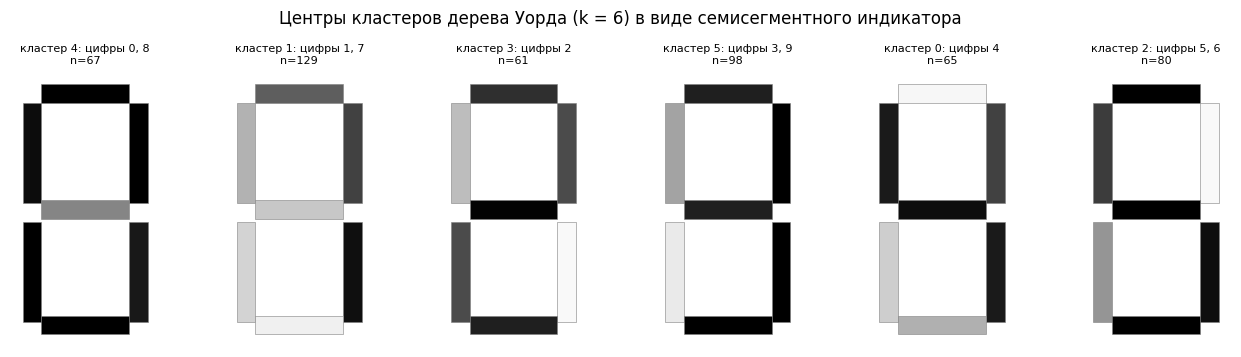

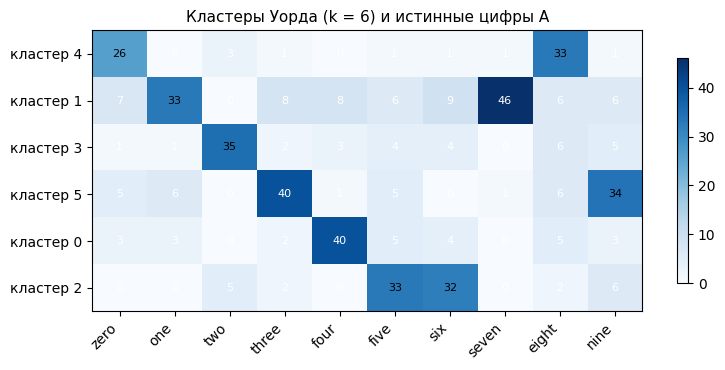

In [29]:
K_FINAL = 6
lab_final = fcluster(Z, K_FINAL, "maxclust") - 1
print(f"Метод Уорда, k = {K_FINAL}: размеры кластеров:", np.bincount(lab_final).tolist())
display(pd.DataFrame({**internal_scores(X, lab_final, "hamming"), **external_scores(lab_final)}, index=[f"Ward (k={K_FINAL})"]).round(3))

ct6 = pd.crosstab(pd.Series(lab_final, name="кластер"), pd.Categorical(y, categories=DIGITS, ordered=True), rownames=["кластер"], colnames=["цифра"])
groups = {c: [d for d in DIGITS if ct6.loc[c, d] >= 0.15 * ct6.loc[c].sum()] for c in ct6.index}
cent6 = pd.DataFrame(X, columns=SEG).groupby(lab_final).mean()
tab6 = pd.DataFrame({"n": ct6.sum(axis=1),
                     "группа цифр (>= 15 %)": [", ".join(str(DIGIT_NUM[d]) for d in groups[c]) for c in ct6.index],
                     "доля группы в кластере": [ct6.loc[c, groups[c]].sum() / ct6.loc[c].sum() for c in ct6.index],
                     "округлённый центр (BCDEFGH)": cent6.round().astype(int).astype(str).agg("".join, axis=1)})
display(tab6.round(2))
cover = sum(ct6.loc[c, g].sum() for c, g in groups.items()) / N
print(f"Доля цифр, попавших в «свою» группу кластера: {cover:.3f}  (чистота по одной цифре: {purity(y, lab_final):.3f})")
display(ct6)

order6 = list(tab6.sort_values("группа цифр (>= 15 %)").index)
fig, axes = plt.subplots(1, 6, figsize=(13, 3.6))
for ax, c in zip(axes, order6):
    draw_digit(ax, cent6.loc[c].to_numpy(), f"кластер {c}: цифры {tab6.loc[c, 'группа цифр (>= 15 %)']}\nn={int(tab6.loc[c, 'n'])}", fs=8)
fig.suptitle("Центры кластеров дерева Уорда (k = 6) в виде семисегментного индикатора")
save_show(fig, "ward6_centroids")

fig, ax = plt.subplots(figsize=(8, 3.8))
im = heatmap(ax, ct6.loc[order6].values, DIGITS, [f"кластер {c}" for c in order6], cmap="Blues", fmt="{:.0f}")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set(title="Кластеры Уорда (k = 6) и истинные цифры A")
save_show(fig, "ward6_crosstab")

**Интерпретация результатов:**

Выделенные шесть кластеров соответствуют **шести группам цифр с близкими топологическими начертаниями**: $\{4\}$, $\{2\}$, $\{1, 7\}$, $\{5, 6\}$, $\{0, 8\}$ и $\{3, 9\}$. Округленные центроиды кластеров совпадают с конкретными эталонными конфигурациями. Центр группы $\{1, 7\}$ соответствует начертанию цифры 7, $\{5, 6\}$ — цифры 5, $\{0, 8\}$ — цифры 8, а $\{3, 9\}$ — цифры 3, то есть центр группы репрезентируется конфигурацией одного из ее реальных представителей. Символы 4 и 2 формируют самостоятельные обособленные кластеры благодаря высокой специфичности и морфологической уникальности их графических паттернов.

Доля профилей целевой группы внутри соответствующего кластера составляет от $0{,}57$ до $0{,}88$, а общая доля объектов, попавших в свою укрупненную группу, равна $0{,}70$ при показателе чистоты по отдельным исходным цифрам, составляющем $0{,}45$.

Объединение знаков в единые кластеры обусловлено их минимальным структурным различием, составляющим ровно один сегмент:
* пары **1 и 7** различаются элементом $B$;
* **5 и 6** — элементом $F$;
* **0 и 8** — элементом $E$;
* **3 и 9** — элементом $C$.

В условиях присутствия порядка $10\,\%$ случайных искажений структуры сегментов столь незначительного межкластерного расстояния оказывается недостаточно для того, чтобы иерархический алгоритм мог надежно дифференцировать данные пары знаков.

## B.5. Проверка более детального разбиения: k = 10

In [30]:
lab_k10 = fcluster(Z, 10, "maxclust") - 1
K_FINAL = 10
print(f"Метод Уорда, k = 10: размеры кластеров:", np.bincount(lab_k10).tolist())
display(pd.DataFrame({**internal_scores(X, lab_k10, "hamming"), **external_scores(lab_k10)}, index=["Ward (k=10)"]).round(3))

Метод Уорда, k = 10: размеры кластеров: [34, 31, 69, 28, 32, 80, 61, 67, 42, 56]


,silhouette,calinski_harabasz,davies_bouldin,ARI,NMI,однородность,полнота,purity
Ward (k=10),0.342,90.511,1.327,0.326,0.45,0.444,0.456,0.508


In [31]:
ct = pd.crosstab(pd.Series(lab_k10, name="кластер"), pd.Categorical(y, categories=DIGITS, ordered=True), rownames=["кластер"], colnames=["истинная цифра"])
dom = ct.idxmax(axis=1)
info = pd.DataFrame({"n": ct.sum(axis=1), "доминирующая цифра": dom, "доля доминирующей": (ct.max(axis=1) / ct.sum(axis=1)).round(2)})
cent = pd.DataFrame(X, columns=SEG).groupby(lab_k10).mean()
info["округлённый центр (BCDEFGH)"] = cent.round().astype(int).astype(str).agg("".join, axis=1)
info["эталон доминирующей"] = [("".join(map(str, CANON[d]))) for d in dom]
info["центр = эталону"] = info["округлённый центр (BCDEFGH)"] == info["эталон доминирующей"]
info = info.sort_values("доминирующая цифра", key=lambda s: s.map(DIGIT_NUM))
display(info)
print("Различных цифр среди доминирующих:", dom.nunique(), "из 10; цифры без собственного кластера:", sorted(set(DIGITS) - set(dom), key=DIGIT_NUM.get))
print("Центры, совпавшие с эталоном доминирующей цифры:", int(info["центр = эталону"].sum()), "из", K_FINAL)
display(ct.loc[info.index])

,n,доминирующая цифра,доля доминирующей,округлённый центр (BCDEFGH),эталон доминирующей,центр = эталону
кластер,,,,,,
6,61,two,0.57,1011101,1011101,True
4,32,three,0.22,1111010,1011011,False
9,56,three,0.62,1011011,1011011,True
0,34,four,0.88,0111010,0111010,True
1,31,four,0.32,0111111,0111010,False
5,80,five,0.41,1101011,1101011,True
3,28,six,0.32,1100010,1101111,False
2,69,seven,0.51,1010010,1010010,True
7,67,eight,0.49,1111111,1111111,True


Различных цифр среди доминирующих: 8 из 10; цифры без собственного кластера: ['zero', 'one']
Центры, совпавшие с эталоном доминирующей цифры: 7 из 10


истинная цифра,zero,one,two,three,four,five,six,seven,eight,nine
кластер,,,,,,,,,,
6,1,1,35,2,3,4,4,0,6,5
4,3,2,0,7,4,1,0,5,5,5
9,4,6,0,35,1,0,0,1,2,7
0,0,3,0,1,30,0,0,0,0,0
1,3,0,0,1,10,5,4,0,5,3
5,0,0,5,2,0,33,32,0,2,6
3,1,2,0,1,3,5,9,6,1,0
2,3,29,0,0,1,0,0,35,0,1
7,26,0,3,1,0,1,1,1,33,1


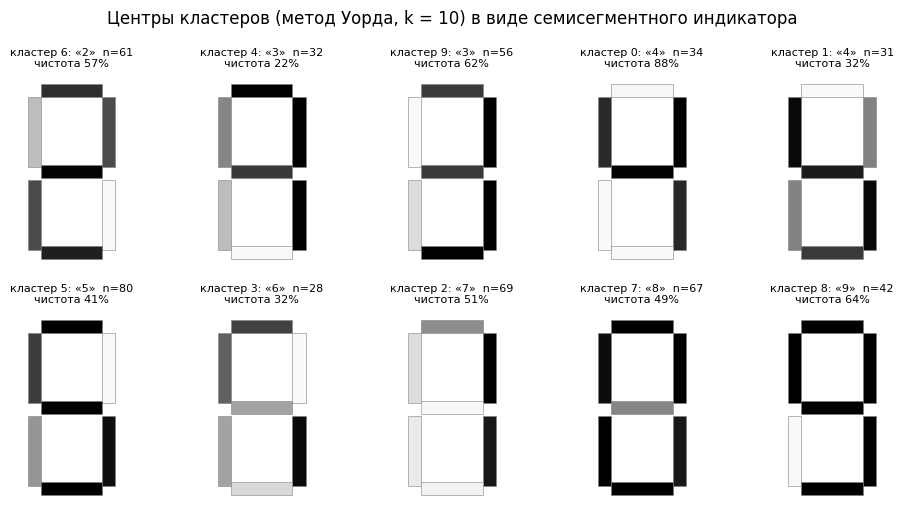

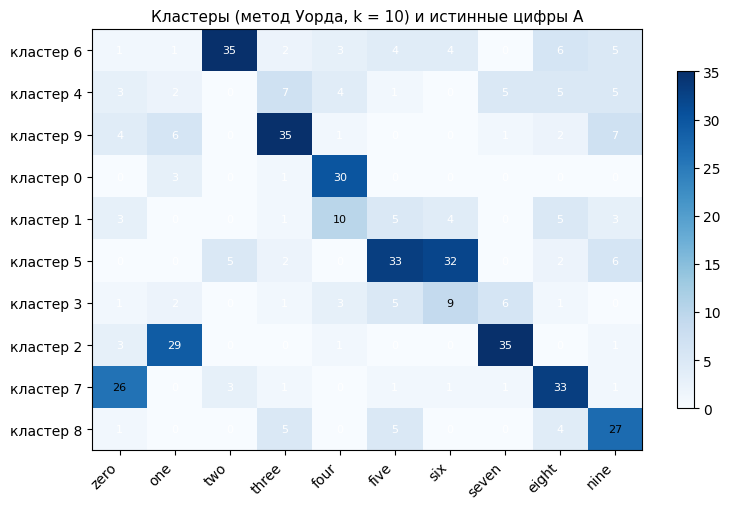

,доминирует,основная примесь,объектов примеси,доля примеси
кластер,,,,
6,two,eight,6,0.10
4,three,eight,5,0.16
9,three,nine,7,0.12
0,four,one,3,0.09
1,four,five,5,0.16
5,five,six,32,0.40
3,six,seven,6,0.21
2,seven,one,29,0.42
7,eight,zero,26,0.39


In [32]:
order = list(info.index)
fig, axes = plt.subplots(2, 5, figsize=(10, 5.2))
for ax, c in zip(axes.ravel(), order):
    draw_digit(ax, cent.loc[c].to_numpy(), f"кластер {c}: «{DIGIT_NUM[dom[c]]}»  n={int(info.loc[c, 'n'])}\nчистота {info.loc[c, 'доля доминирующей']:.0%}")
fig.suptitle("Центры кластеров (метод Уорда, k = 10) в виде семисегментного индикатора")
save_show(fig, "centroids")

fig, ax = plt.subplots(figsize=(8, 5.2))
im = heatmap(ax, ct.loc[order].values, DIGITS, [f"кластер {c}" for c in order], cmap="Blues", fmt="{:.0f}")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set(title="Кластеры (метод Уорда, k = 10) и истинные цифры A")
save_show(fig, "crosstab")

conf = ct.loc[order].copy()
rows = []
for c in order:
    other = conf.loc[c].drop(dom[c]).sort_values(ascending=False)
    rows.append({"кластер": c, "доминирует": dom[c], "основная примесь": other.index[0], "объектов примеси": int(other.iloc[0]), "доля примеси": round(other.iloc[0] / conf.loc[c].sum(), 2)})
display(pd.DataFrame(rows).set_index("кластер"))

**Заключение:**

При $k = 10$ метод Уорда **не обеспечивает точного восстановления алфавита цифровых знаков**: доминирующие цифры представлены лишь в 8 из 10 кластеров. Для нуля и единицы самостоятельные кластеры не выделяются: нули распределяются в единую группу с восьмерками — 26 и 33 объекта соответственно, а единицы — с семёрками, 29 и 35 объектов. Только 7 из 10 округленных центроидов совпадают с эталонными начертаниями; чистота разбиения составляет $0{,}51$, индекс $ARI$ — $0{,}33$, $NMI$ — $0{,}45$, а устойчивость находится на уровне $0{,}58$.

Главная причина описанного ограничения заключается в характере агломеративной процедуры: в условиях зашумленности данных ошибочные слияния, совершенные на ранних итерациях, не подлежат коррекции на последующих шагах. Для дифференциации объектов на уровне отдельных цифр более целесообразно использовать алгоритмы, оптимизирующие целевую функцию глобально, в частности, метод $k$-средних.

In [33]:
Path("results").mkdir(exist_ok=True)
out = raw[["A"]].copy(); out[SEG] = X
out["cluster_ward_k6"] = lab_final
out["cluster_ward_k10"] = lab_k10
out.to_csv("results/lab1_digits_clusters_ward.csv", index=False, encoding="utf-8-sig")
print("Сохранено: results/lab1_digits_clusters_ward.csv")

Сохранено: results/lab1_digits_clusters_ward.csv


### Выводы по части B

1. **Характеристика исходных данных:** Кодирование сегментов в описании данных инвертировано относительно фактических значений. Значению `ONE` соответствует активное состояние сегмента, что обеспечивает согласие с эталонными начертаниями на уровне 90 % против 10 % при противоположной трактовке; дублирующие переменные исключены. В данных зафиксировано около 10 % искаженных сегментов, при этом полностью безошибочная запись характерна лишь для 49 % наблюдений. Абсолютный предел точности классификации по критерию ближайшего эталона составляет 0,746.
2. **Выбор метода межгруппового связывания:** В качестве базового выбран метод Уорда. Алгоритм одиночной связи признан непригодным из-за выраженного эффекта цепеобразования; методы полного и взвешенного связывания уступают по ключевым критериям; метод среднего расстояния сопоставим по точности, однако формирует существенно неуравновешенные по мощности кластеры.
3. **Обоснование числа кластеров:** На основе анализа дендрограммы принято решение о фиксации **$k = 6$** как наиболее значимого локального скачока высоты слияния после тривиального разбиения при $k = 2$. Полученные шесть кластеров объединяют группы морфологически близких символов: $\{4\}$, $\{2\}$, $\{1, 7\}$, $\{5, 6\}$, $\{0, 8\}$ и $\{3, 9\}$. Доля объектов, корректно распределенных по своим укрупненным группам, составляет 0,70.
4. **Методические ограничения:** Разбиение на 10 кластеров методом Уорда демонстрирует неудовлетворительное качество. Чистота составляет 0,51; цифры 0 и 1 не формируют самостоятельных кластеров; устойчивость иерархического дерева на подвыборках находится на умеренном уровне $ARI = 0{,}48–0{,}65$ при $k = 6–14$. Истинное значение цифры привлекалось исключительно в качестве внешнего критерия для содержательной интерпретации и верификации результатов.

## Общие выводы по лабораторной работе 1

1. **Эффективность метода:** Применение иерархического алгоритма (метод Уорда с евклидовой метрикой для непрерывных данных; метод Уорда на бинарных $0/1$-признаках, эквивалентный расстоянию Хэмминга, для цифр) продемонстрировало **высокую четкость и абсолютную устойчивость на данных потребительских предпочтений** (сформировано четыре сегмента), а также позволило получить **адекватную укрупненную структуризацию зашумленных бинарных данных** (выделено шесть парных групп морфологически близких символов).

2. **Обоснование количества кластеров:** Оптимальная мощность разбиения установлена на основе анализа локальных скачков высоты объединения на дендрограмме и верифицирована системой внутренних индексов и критерием устойчивости на подвыборках: **$k = 4$** для исследования потребительского спроса и **$k = 6$** для анализа цифровых начертаний.

3. **Иерархическая топология:**
   * *В сегментации потребителей:* Наибольшую степень обособленности проявляет сегмент «Здоровье», в то время как группы «Сладкое» и «Фокус» демонстрируют максимальную близкую мотивационную направленность.
   * *В структурировании цифр:* Алгоритм агломерирует в единые группы пары знаков, различающиеся ровно одним сегментным элементом ($\{1, 7\}$, $\{5, 6\}$, $\{0, 8\}$ и $\{3, 9\}$).

4. **Ограничения применимости:** Для задачи распознавания бинарных знаков иерархический подход на уровне $k = 10$ демонстрирует ограниченную эффективную мощность из-за невозможности коррекции ошибок первичных слияний в условиях присутствия зашумленности. Для полной дифференциации объектов на уровне отдельных классов целесообразно привлекать оптимизационные и плотностные методы кластеризации, например $k$-средних и DBSCAN.